# Project 10: Overfitting and Underfitting Analysis

**Subject:** Artificial Neural Networks / Deep Learning  
**Dataset:** Iris flower classification dataset  
**Objective:** To compare neural networks with different levels of complexity and identify underfitting, appropriate fitting, and overfitting.


## Introduction
In this project, I use the Iris dataset to study how the complexity of a neural network affects its performance. I train three models using the same training and testing data. I compare training accuracy and testing accuracy to understand whether each model is underfitting, fitting appropriately, or overfitting.

The Iris dataset contains measurements of iris flowers and three target classes: Setosa, Versicolor, and Virginica.


## 1. Import the required libraries

I use `pandas` to organize the results, `matplotlib` to visualize the comparison, and scikit-learn to load the Iris dataset, split it into training and testing sets, scale the features, and build neural network classifiers. I set random states so the experiment can be repeated consistently.

In [1]:
import warnings
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.pipeline import make_pipeline
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix


## 2. Load and inspect the Iris dataset

I load the built-in Iris dataset, then display the first few rows and the number of samples and features. This helps me confirm what data the models will learn from.

In [2]:
iris = load_iris()

X = pd.DataFrame(iris.data, columns=iris.feature_names)
y = pd.Series(iris.target, name="species")

print("Dataset shape:", X.shape)
print("Number of classes:", len(np.unique(y)))
print("\nClass names:", list(iris.target_names))
display(X.head())


Dataset shape: (150, 4)
Number of classes: 3

Class names: [np.str_('setosa'), np.str_('versicolor'), np.str_('virginica')]


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm)
0,5.1,3.5,1.4,0.2
1,4.9,3.0,1.4,0.2
2,4.7,3.2,1.3,0.2
3,4.6,3.1,1.5,0.2
4,5.0,3.6,1.4,0.2


## 3. Split the data once

I use 70% of the data for training and 30% for testing. The `stratify=y` option keeps the class proportions similar in both sets. I create this split only once and reuse it for every model, so the comparison is fair. Feature scaling is included inside each pipeline and is fitted only on the training data to avoid data leakage.

In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nTraining class counts:")
print(y_train.value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))))
print("\nTesting class counts:")
print(y_test.value_counts().sort_index().rename(index=dict(enumerate(iris.target_names))))


Training samples: 105
Testing samples: 45

Training class counts:
species
setosa        35
versicolor    35
virginica     35
Name: count, dtype: int64

Testing class counts:
species
setosa        15
versicolor    15
virginica     15
Name: count, dtype: int64


## 4. Build neural networks with different complexity

I compare three architectures:

- **Simple model:** one hidden neuron. This model has limited capacity and is used to demonstrate underfitting.
- **Balanced model:** one hidden layer with 8 neurons. This model has more capacity while remaining relatively simple.
- **Complex model:** three hidden layers with 100 neurons each and very weak regularization. This model has much greater capacity and may fit the training data extremely closely, which can lead to overfitting.

All models use the same training and testing sets. The models use the `lbfgs` optimizer, which is suitable for this small dataset. Since training outcomes can vary by software version, I use the measured scores below rather than assuming a model's behavior in advance.

In [4]:
models = {
    "Simple (1 neuron)": MLPClassifier(
        hidden_layer_sizes=(1,),
        activation="relu",
        solver="lbfgs",
        alpha=0.01,
        max_iter=3000,
        random_state=42
    ),
    "Balanced (8 neurons)": MLPClassifier(
        hidden_layer_sizes=(8,),
        activation="relu",
        solver="lbfgs",
        alpha=0.001,
        max_iter=3000,
        random_state=42
    ),
    "Complex (100-100-100)": MLPClassifier(
        hidden_layer_sizes=(100, 100, 100),
        activation="relu",
        solver="lbfgs",
        alpha=1e-6,
        max_iter=3000,
        random_state=42
    )
}


## 5. Train and evaluate all models

For each model, I train on the same training set and calculate accuracy on both the training and testing sets. I also calculate the accuracy gap (`training accuracy − testing accuracy`). A large positive gap can be a sign of overfitting, while low scores on both sets can indicate underfitting.

In [5]:
results = []
fitted_models = {}

for name, classifier in models.items():
    pipeline = make_pipeline(StandardScaler(), classifier)
    pipeline.fit(X_train, y_train)

    train_pred = pipeline.predict(X_train)
    test_pred = pipeline.predict(X_test)

    train_acc = accuracy_score(y_train, train_pred)
    test_acc = accuracy_score(y_test, test_pred)

    results.append({
        "Model": name,
        "Training Accuracy": train_acc,
        "Testing Accuracy": test_acc,
        "Accuracy Gap": train_acc - test_acc
    })
    fitted_models[name] = pipeline

results_df = pd.DataFrame(results)
display(
    results_df.style.format({
        "Training Accuracy": "{:.2%}",
        "Testing Accuracy": "{:.2%}",
        "Accuracy Gap": "{:.2%}"
    })
)


,Model,Training Accuracy,Testing Accuracy,Accuracy Gap
0,Simple (1 neuron),100.00%,91.11%,8.89%
1,Balanced (8 neurons),100.00%,91.11%,8.89%
2,Complex (100-100-100),100.00%,88.89%,11.11%


## 6. Visualize the comparison

The first chart compares training and testing accuracy. The second chart shows the accuracy gap. I use both charts because testing accuracy alone does not tell the full story: a model can score highly on training data but perform noticeably worse on unseen data.

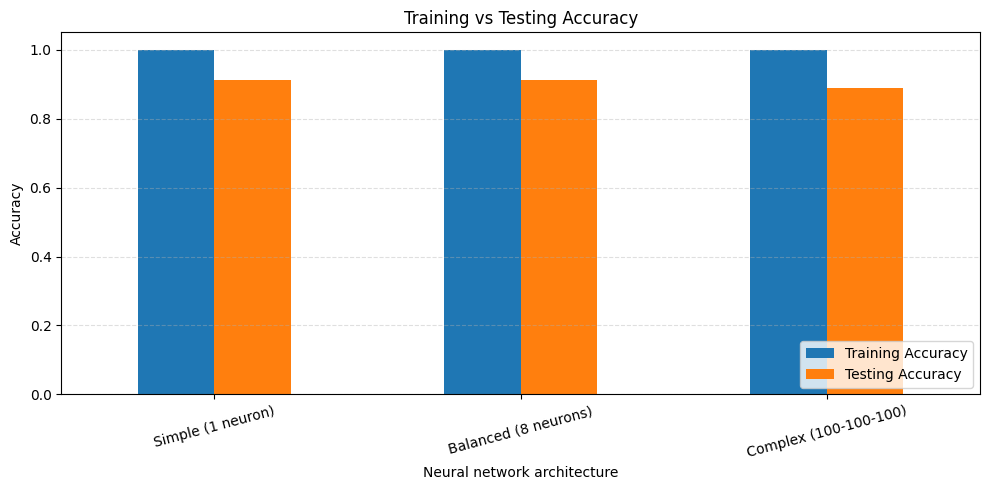

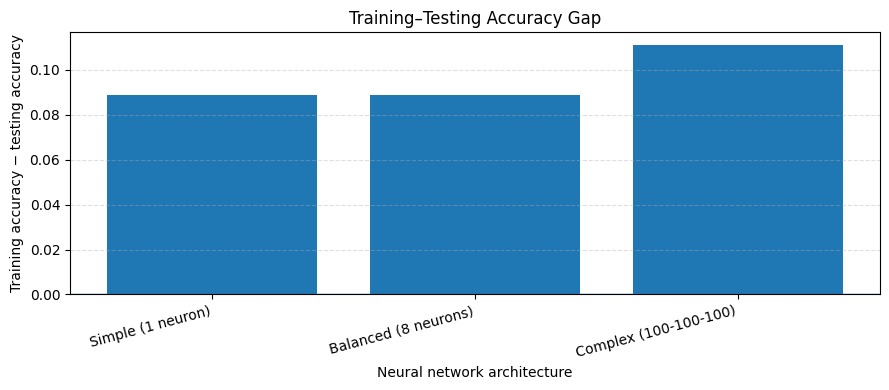

In [6]:
plot_df = results_df.set_index("Model")

ax = plot_df[["Training Accuracy", "Testing Accuracy"]].plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1.05), rot=15
)
ax.set_title("Training vs Testing Accuracy")
ax.set_ylabel("Accuracy")
ax.set_xlabel("Neural network architecture")
ax.legend(loc="lower right")
ax.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
plt.bar(results_df["Model"], results_df["Accuracy Gap"])
plt.title("Training–Testing Accuracy Gap")
plt.ylabel("Training accuracy − testing accuracy")
plt.xlabel("Neural network architecture")
plt.xticks(rotation=15, ha="right")
plt.axhline(0, linewidth=1)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()


## 7. Interpret the results

I use these general rules to interpret the measured results:

- **Underfitting:** training and testing accuracy are both relatively low. The model may be too simple to learn the patterns in the dataset.
- **Appropriate fitting:** training and testing accuracy are both good and reasonably close. The model learns useful patterns and generalizes to unseen data.
- **Overfitting:** training accuracy is much higher than testing accuracy. The model may have learned details specific to the training set instead of patterns that generalize.

The labels below are based on the actual scores from this run. These are practical indicators rather than strict universal thresholds.

In [7]:
def classify_fit(row):
    train = row["Training Accuracy"]
    test = row["Testing Accuracy"]
    gap = row["Accuracy Gap"]

    if train < 0.80 and test < 0.80:
        return "Likely underfitting"
    elif gap >= 0.10:
        return "Possible overfitting"
    elif train >= 0.85 and test >= 0.85 and abs(gap) < 0.10:
        return "Reasonably appropriate fit"
    elif gap >= 0.05:
        return "Some overfitting risk"
    else:
        return "Needs closer inspection"

results_df["Interpretation"] = results_df.apply(classify_fit, axis=1)
display(
    results_df.style.format({
        "Training Accuracy": "{:.2%}",
        "Testing Accuracy": "{:.2%}",
        "Accuracy Gap": "{:.2%}"
    })
)

print("\nInterpretation by model:")
for _, row in results_df.iterrows():
    print(f"- {row['Model']}: {row['Interpretation']}")


,Model,Training Accuracy,Testing Accuracy,Accuracy Gap,Interpretation
0,Simple (1 neuron),100.00%,91.11%,8.89%,Reasonably appropriate fit
1,Balanced (8 neurons),100.00%,91.11%,8.89%,Reasonably appropriate fit
2,Complex (100-100-100),100.00%,88.89%,11.11%,Possible overfitting



Interpretation by model:
- Simple (1 neuron): Reasonably appropriate fit
- Balanced (8 neurons): Reasonably appropriate fit
- Complex (100-100-100): Possible overfitting


## 8. Detailed evaluation of the balanced model

I inspect the classification report and confusion matrix for the balanced model. Precision, recall, and F1-score show performance for each flower class, while the confusion matrix shows how many predictions were correct or confused with another class.

In [8]:
balanced_name = "Balanced (8 neurons)"
balanced_model = fitted_models[balanced_name]
balanced_pred = balanced_model.predict(X_test)

print("Classification report for", balanced_name)
print(classification_report(
    y_test, balanced_pred,
    labels=[0, 1, 2],
    target_names=iris.target_names,
    zero_division=0
))

cm = confusion_matrix(y_test, balanced_pred, labels=[0, 1, 2])
cm_df = pd.DataFrame(cm, index=iris.target_names, columns=iris.target_names)
print("Confusion matrix (rows = actual, columns = predicted):")
display(cm_df)


Classification report for Balanced (8 neurons)
              precision    recall  f1-score   support

      setosa       1.00      1.00      1.00        15
  versicolor       0.79      1.00      0.88        15
   virginica       1.00      0.73      0.85        15

    accuracy                           0.91        45
   macro avg       0.93      0.91      0.91        45
weighted avg       0.93      0.91      0.91        45

Confusion matrix (rows = actual, columns = predicted):


,setosa,versicolor,virginica
setosa,15,0,0
versicolor,0,15,0
virginica,0,4,11


## 9. Methods to improve the model

Based on the comparison, I would consider the following improvements:

1. **If the model underfits:** increase the number of hidden neurons, try another hidden-layer structure, train for enough iterations, or use a more suitable activation function.
2. **If the model overfits:** reduce the number of neurons or hidden layers, increase regularization (`alpha`), collect more training examples, or use cross-validation to select model settings.
3. **For a fair evaluation:** keep the test set separate until final evaluation, use a stratified split, and fit preprocessing steps only on training data.
4. **For a more reliable conclusion:** repeat the experiment with several random seeds or use stratified cross-validation. Iris is a small and relatively easy dataset, so even a complex model may achieve high test accuracy in one split.

The best model should not be selected only because it has the highest training accuracy. I should consider test performance, the training–testing gap, and model simplicity together.

## 10. Conclusion

In this project, I trained neural network classifiers with different architectures on the Iris dataset and evaluated them using the same training and testing sets. Comparing training accuracy, testing accuracy, and the accuracy gap helps me understand the difference between underfitting and overfitting.

A model that is too simple may fail to learn the data patterns, while a very complex model can memorize the training examples and generalize less effectively. The most suitable model is the one that achieves good testing performance with a reasonably small gap between training and testing accuracy. The measured results and charts above provide the evidence for deciding how each model behaved in this experiment.


